# Лабораторная работа 1. Численные методы линейной алгебры в задаче наименьших квадратов

## 1. Цель и постановка задачи

В линейной регрессии мы вычисляем прогноз как $X\beta$. Метод наименьших квадратов подбирает коэффициенты так, чтобы минимизировать сумму квадратов ошибок. В точке минимума остаток $y-X\hat\beta$ ортогонален каждому столбцу $X$: из этого условия получаем нормальные уравнения.

Исследуем, как стандартизация, обусловленность и потеря ранга влияют на решение задачи наименьших квадратов (МНК). Сравним LU-разложение нормальных уравнений, разложение Холецкого, метод Зейделя и решение через сингулярное разложение (SVD), а также усечённое SVD и ridge-регуляризацию.

Для матрицы признаков со столбцом единиц $X$ и вектора прочности $y$ решаем задачу
$$
\min_\beta \|X\beta-y\|_2^2,\qquad
A\beta=b,\quad A=X^\top X,\quad b=X^\top y.
$$

Основная метрика прогноза: $\mathrm{RMSE}=\sqrt{\frac1n\sum_i(\hat y_i-y_i)^2}$ в МПа. Для численного сравнения используем относительный остаток нормальных уравнений $\|A\beta-b\|_2/\|b\|_2$ и относительный остаток МНК $\|X\beta-y\|_2/\|y\|_2$. Последний включает ошибку линейной аппроксимации данных.

## 2. Исходные данные

В задаче регрессии строка таблицы соответствует одному наблюдению. Состав смеси и возраст образца служат признаками, а измеренная прочность на сжатие служит целевой переменной. Повторяющиеся комбинации признаков могут соответствовать разным измерениям прочности.

**Concrete Compressive Strength**, I.-C. Yeh (1998), UCI Machine Learning Repository, [источник](https://doi.org/10.24432/C5PK67), [статья](https://doi.org/10.1016/S0008-8846(98)00165-3). Используем поставляемый с работой файл `data/Concrete_Data.xls`, преобразованный в формат `csv`. Единицы и порядок столбцов указаны в `data/Concrete_Readme.txt`.

| Столбец | Содержание | Единицы |
|---|---|---|
| `cement` | Цемент | кг/м³ |
| `slag` | Доменный шлак | кг/м³ |
| `fly_ash` | Зола-унос | кг/м³ |
| `water` | Вода | кг/м³ |
| `superplasticizer` | Суперпластификатор | кг/м³ |
| `coarse_aggregate` | Крупный заполнитель | кг/м³ |
| `fine_aggregate` | Мелкий заполнитель | кг/м³ |
| `age` | Возраст образца | дни |
| `strength` | Измеренная прочность на сжатие, целевая переменная | МПа |

Для запуска требуется ядро Python с пакетами `numpy`, `pandas`, `scipy`, `matplotlib`, `scikit-learn`, `ipykernel`. В вычислительных разделах используем библиотечные факторизации, треугольное решение систем и SVD из SciPy и NumPy. Итерацию Зейделя записываем по её матричной формуле.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.linalg import LinAlgWarning, cho_factor, cho_solve, lu_factor, lu_solve, solve_triangular
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler


FEATURES = [
    "cement", "slag", "fly_ash", "water", "superplasticizer",
    "coarse_aggregate", "fine_aggregate", "age",
]
TARGET = "strength"
SEED = 42

data_path = Path("data/Concrete_Data.csv")
if not data_path.is_file():
    data_path = Path("lab-1") / data_path

data = pd.read_csv(data_path)
data.columns = [*FEATURES, TARGET]
data = data.apply(pd.to_numeric, errors="raise")
missing_count = int(data.isna().sum().sum())
assert len(data) == 1030 and missing_count == 0

groups = data.groupby(FEATURES, sort=False).ngroup().to_numpy()
strength_counts = data.groupby(FEATURES)[TARGET].nunique()
display(data.head())
display(pd.Series({
    "Наблюдений": len(data),
    "Признаков": len(FEATURES),
    "Пропусков": missing_count,
    "Уникальных комбинаций признаков": np.unique(groups).size,
    "Комбинаций с разной измеренной прочностью": int((strength_counts > 1).sum()),
}).to_frame("Количество"))

,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


,Количество
Наблюдений,1030
Признаков,8
Пропусков,0
Уникальных комбинаций признаков,996
Комбинаций с разной измеренной прочностью,9


Пропусков нет, поэтому используем все 1030 строк. У некоторых образцов при одинаковых восьми входных значениях зафиксирована разная прочность. Такие наблюдения подтверждают, что цель нельзя однозначно восстановить из признаков.

### 2.1. Подготовка обучающей и тестовой частей

На обучающей части оцениваем коэффициенты, а на отложенной тестовой части измеряем ошибку прогноза на новых комбинациях признаков. Групповое разбиение удерживает повторные наблюдения одной комбинации в одной части. Стандартизатор оценивает параметры по обучающим строкам и применяет их к тестовым, чтобы исключить утечку информации из теста.

Около 20% групп отводим под тест. Группу определяем по совпадению всех восьми признаков, включая возраст. Наблюдения внутри группы сохраняем и целиком относим к одной части выборки. Выполняем разбиение с `random_state=42` и используем его во всех опытах. Параметр ridge выбираем по групповой кросс-валидации внутри обучающей части.

Стандартизация использует среднее и стандартное отклонение обучающих признаков. Свободный член задаём первым столбцом единиц и сохраняем во всех задачах, включая усечённое SVD. При ridge исключаем этот коэффициент из штрафа.

In [3]:
def add_intercept(features):
    return np.column_stack((np.ones(features.shape[0]), features))


splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(data, groups=groups))
assert len(np.intersect1d(groups[train_idx], groups[test_idx])) == 0

features = data[FEATURES].to_numpy(dtype=float)
target = data[TARGET].to_numpy(dtype=float)
train_raw, test_raw = features[train_idx], features[test_idx]
y_train, y_test = target[train_idx], target[test_idx]

scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_raw)
test_scaled = scaler.transform(test_raw)
X_train_raw = add_intercept(train_raw)
X_train = add_intercept(train_scaled)
X_test = add_intercept(test_scaled)

display(pd.DataFrame({
    "Наблюдения": [len(train_idx), len(test_idx)],
    "Группы": [np.unique(groups[train_idx]).size, np.unique(groups[test_idx]).size],
}, index=["Обучение", "Тест"]))

,Наблюдения,Группы
Обучение,826,796
Тест,204,200


В обучение вошли 826 строк из 796 групп, в тест попали 204 строки из 200 групп. Доля тестовых строк составила 19,8%, поскольку при разбиении отбирают группы, а число наблюдений в них различается.

## 3. Исследование матрицы данных (§ 1.4.1)

Ранг показывает число линейно независимых направлений в столбцах матрицы. Число обусловленности характеризует чувствительность задачи к возмущениям. Большой разброс сингулярных значений указывает, что изменения коэффициентов по разным направлениям влияют на прогноз с разной силой. Корреляция Пирсона измеряет линейную связь двух признаков и принимает значения от $-1$ до $1$.

Численный ранг равен числу сингулярных значений $\sigma_i>\tau$, где
$$\tau=\max(n,p)\,\varepsilon_{\mathrm{mach}}\,\sigma_{\max}.$$
При полном столбцовом ранге $\kappa_2(X)=\sigma_{\max}/\sigma_{\min}$. Обусловленность $X^\top X$ отдельно вычисляем по его сингулярным значениям. В точной арифметике $\kappa_2(X^\top X)=\kappa_2(X)^2$. При численной потере столбцового ранга $X$ отмечаем обусловленность обеих задач как бесконечную. Отдельное вычисление по сформированной матрице $X^\top X$ полезно при почти вырожденной задаче, где округление может влиять на её минимальное сингулярное значение.

Ранг и числа обусловленности рассчитываем со столбцом единиц. Корреляционную матрицу Пирсона строим по восьми количественным признакам на обучающей части.

Матрицы корреляций до и после стандартизации совпадают с численной точностью. Для двух признаков $x$ и $y$ преобразование $x'=(x-\bar x)/\sigma_x$, $y'=(y-\bar y)/\sigma_y$ сохраняет коэффициент Пирсона. Вычитание средних не влияет на ковариацию, а деление на стандартные отклонения масштабирует ковариацию и произведение стандартных отклонений одинаково. Поэтому множители сокращаются:
$$
r(x',y') = \frac{\operatorname{cov}(x',y')}{\operatorname{std}(x')\operatorname{std}(y')} = \frac{\operatorname{cov}(x,y)}{\sigma_x\sigma_y} = r(x,y).
$$
Число обусловленности $\kappa_2(X)$ зависит от масштаба столбцов, поэтому стандартизация может его уменьшить при тех же парных корреляциях.

,Ранг,Допуск,κ₂(X),κ₂(XᵀX)
До стандартизации,9,6.81e-09,1.063e+05,1.13e+10
После стандартизации,9,7.89e-12,8.608,74.09


,До стандартизации,После стандартизации
Номер σ,,
1,3.716e+04,43.04
2,3305,34.44
3,2620,33.25
4,2433,28.89
5,1809,28.74
6,1397,28.42
7,709.1,25.54
8,104.3,12.01
9,0.3496,5


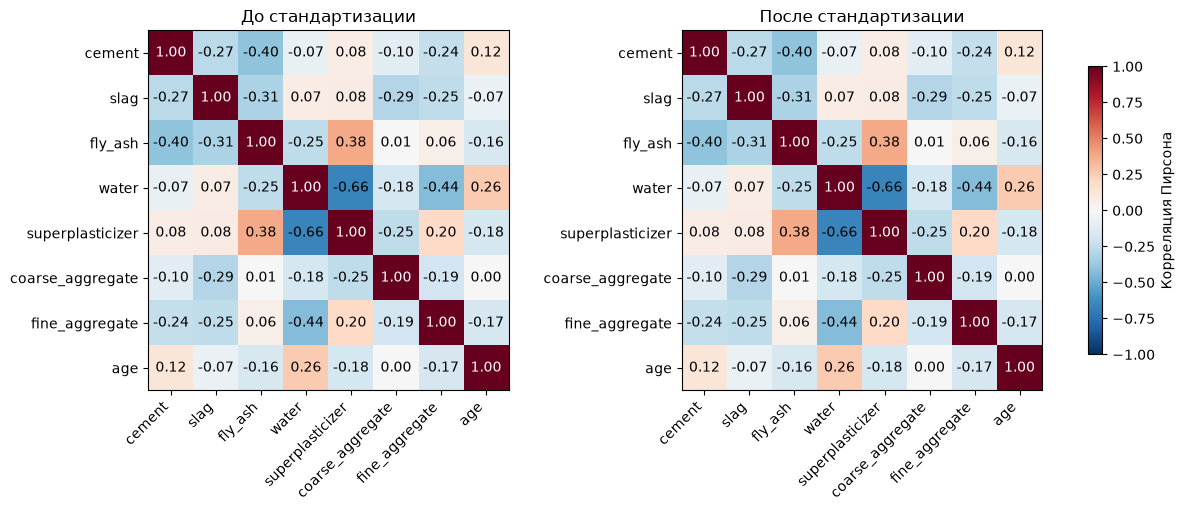

В обоих случаях ранг равен 9. Стандартизация снизила κ₂(X) с 1.06e+05 до 8.61. Самая сильная парная корреляция наблюдается между `water` и `superplasticizer` (-0.66). Корреляции сохранились при стандартизации, поскольку каждый признак был сдвинут и умножен на положительную константу. Столбцы сохраняют линейную независимость в пределах выбранного допуска.

In [3]:
def rank_threshold(matrix, singular_values):
    return max(matrix.shape) * np.finfo(matrix.dtype).eps * singular_values[0]


def matrix_diagnostics(matrix):
    singular_values = np.linalg.svd(matrix, compute_uv=False)
    threshold = rank_threshold(matrix, singular_values)
    rank = int(np.count_nonzero(singular_values > threshold))
    full_rank = rank == matrix.shape[1]
    return {
        "Ранг": rank,
        "Допуск": threshold,
        "κ₂(X)": singular_values[0] / singular_values[-1] if full_rank else np.inf,
        "κ₂(XᵀX)": np.linalg.cond(matrix.T @ matrix) if full_rank else np.inf,
    }, singular_values


raw_diagnostics, raw_sigma = matrix_diagnostics(X_train_raw)
scaled_diagnostics, scaled_sigma = matrix_diagnostics(X_train)

display(pd.DataFrame({
    "До стандартизации": raw_diagnostics,
    "После стандартизации": scaled_diagnostics,
}).T.style.format({"Ранг": "{:.0f}", "Допуск": "{:.2e}", "κ₂(X)": "{:.4g}", "κ₂(XᵀX)": "{:.4g}"}))

display(pd.DataFrame({
    "До стандартизации": raw_sigma,
    "После стандартизации": scaled_sigma,
}, index=pd.Index(range(1, len(raw_sigma) + 1), name="Номер σ")).style.format("{:.4g}"))

corr_raw = pd.DataFrame(train_raw, columns=FEATURES).corr()
corr_scaled = pd.DataFrame(train_scaled, columns=FEATURES).corr()
np.testing.assert_allclose(corr_raw, corr_scaled, atol=1e-12)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for ax, corr, title in zip(
    axes, (corr_raw, corr_scaled), ("До стандартизации", "После стандартизации")
):
    image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha="right")
    ax.set_yticks(range(len(FEATURES)), FEATURES)
    ax.set_title(title)
    for row, values in enumerate(corr.to_numpy()):
        for col, value in enumerate(values):
            color = "white" if abs(value) > 0.68 else "black"
            ax.text(col, row, f"{value:.2f}", ha="center", va="center", color=color)
fig.colorbar(image, ax=axes, shrink=0.8, label="Корреляция Пирсона")
plt.show()

correlations = corr_raw.where(np.triu(np.ones(corr_raw.shape, dtype=bool), k=1)).stack()
strongest_pair = correlations.abs().idxmax()
strongest_value = correlations.loc[strongest_pair]
display(Markdown(
    f"В обоих случаях ранг равен {scaled_diagnostics['Ранг']}. "
    f"Стандартизация снизила κ₂(X) с {raw_diagnostics['κ₂(X)']:.3g} "
    f"до {scaled_diagnostics['κ₂(X)']:.3g}. Самая сильная парная корреляция "
    f"наблюдается между `{strongest_pair[0]}` и `{strongest_pair[1]}` "
    f"({strongest_value:.2f}). Корреляции сохранились при стандартизации, "
    "поскольку каждый признак был сдвинут и умножен на положительную константу. "
    "Столбцы сохраняют линейную независимость в пределах выбранного допуска."
))

Корреляция $-0.66$ между содержанием воды и суперпластификатора указывает на обратную линейную связь в обучающей выборке. Матрица корреляций описывает связи между парами признаков, а проверка численного ранга учитывает совместные линейные зависимости между всеми столбцами.

## 4. Прямое решение нормальных уравнений (§ 1.4.2)

LU-разложение с перестановками записывает матрицу системы в виде $PA=LU$, где $P$ переставляет строки, а $L$ и $U$ являются нижней и верхней треугольными матрицами. Сначала прямой подстановкой находят $z$ из $Lz=Pb$, затем обратной подстановкой находят $\beta$ из $U\beta=z$. При полном столбцовом ранге $X$ матрица $A=X^\top X$ симметрична и положительно определена. Это позволяет использовать разложение Холецкого с одним треугольным множителем.

Для прямого решения используем LU-разложение $A$ с перестановками строк. Уравнение проверяем вызовом `numpy.linalg.solve`. Разложением Холецкого отдельно проверяем, можно ли вычислить $A=LL^\top$. Явную обратную матрицу не вычисляем.

In [4]:
def solve_lu(matrix, rhs):
    with warnings.catch_warnings():
        warnings.simplefilter("error", LinAlgWarning)
        factor = lu_factor(matrix)
    return lu_solve(factor, rhs)


def rmse(actual, predicted):
    return np.sqrt(np.mean((actual - predicted) ** 2))


def relative_residual(matrix, beta, rhs):
    return np.linalg.norm(matrix @ beta - rhs) / np.linalg.norm(rhs)


def evaluate(beta, train_matrix, test_matrix, normal_matrix, rhs):
    return {
        "‖β‖₂": np.linalg.norm(beta),
        "Отн. остаток норм. ур.": relative_residual(normal_matrix, beta, rhs),
        "Отн. остаток МНК": relative_residual(train_matrix, beta, y_train),
        "RMSE обучение, МПа": rmse(y_train, train_matrix @ beta),
        "RMSE тест, МПа": rmse(y_test, test_matrix @ beta),
    }


def baseline_metrics(beta):
    return evaluate(beta, X_train, X_test, A, b)


A = X_train.T @ X_train
b = X_train.T @ y_train
beta_lu = solve_lu(A, b)
beta_reference = np.linalg.solve(A, b)
direct_solutions = {"LU": beta_lu, "numpy.linalg.solve": beta_reference}

try:
    chol = cho_factor(A, lower=True)
except np.linalg.LinAlgError as error:
    display(Markdown(
        f"Разложение Холецкого остановлено: {error} "
        f"Ранг X равен {scaled_diagnostics['Ранг']} из {X_train.shape[1]}, "
        f"минимальное собственное число A равно {np.linalg.eigvalsh(A)[0]:.3e}."
    ))
else:
    direct_solutions["Холецкий"] = cho_solve(chol, b)
    display(Markdown(
        "Разложение Холецкого выполнено. "
        f"Минимальное собственное число A равно {np.linalg.eigvalsh(A)[0]:.3g}."
    ))

coefficient_names = ["Свободный член", *FEATURES]
display(pd.DataFrame(direct_solutions, index=coefficient_names).style.format("{:.6f}"))
direct_results = pd.DataFrame({
    name: baseline_metrics(beta) for name, beta in direct_solutions.items()
}).T
direct_results["‖β − β_LU‖₂"] = [
    np.linalg.norm(beta - beta_lu) for beta in direct_solutions.values()
]
display(direct_results.style.format("{:.4g}"))

display(Markdown(
    f"LU даёт тестовый RMSE {direct_results.loc['LU', 'RMSE тест, МПа']:.3f} МПа. "
    f"Наибольшее расхождение коэффициентов с LU составляет "
    f"{direct_results['‖β − β_LU‖₂'].max():.2e}. "
    "Малый остаток нормальных уравнений показывает точность их решения. "
    "Остаток МНК отражает величину ошибки линейной аппроксимации."
))

Разложение Холецкого выполнено. Минимальное собственное число A равно 25.

,LU,numpy.linalg.solve,Холецкий
Свободный член,36.023049,36.023049,36.023049
cement,12.621078,12.621078,12.621078
slag,8.473261,8.473261,8.473261
fly_ash,5.131771,5.131771,5.131771
water,-3.423330,-3.423330,-3.423330
superplasticizer,2.109488,2.109488,2.109488
coarse_aggregate,1.387876,1.387876,1.387876
fine_aggregate,1.658256,1.658256,1.658256
age,6.908694,6.908694,6.908694


,‖β‖₂,Отн. остаток норм. ур.,Отн. остаток МНК,"RMSE обучение, МПа","RMSE тест, МПа",‖β − β_LU‖₂
LU,40.29,7.267e-17,0.2588,10.31,10.65,0
numpy.linalg.solve,40.29,1.375e-16,0.2588,10.31,10.65,1.196e-14
Холецкий,40.29,2.366e-16,0.2588,10.31,10.65,1.997e-14


LU даёт тестовый RMSE 10.646 МПа. Наибольшее расхождение коэффициентов с LU составляет 2.00e-14. Малый остаток нормальных уравнений показывает точность их решения. Остаток МНК отражает величину ошибки линейной аппроксимации.

Положительное минимальное собственное число $A$ подтверждает применимость Холецкого в этом опыте. Малый остаток $\|A\hat\beta-b\|_2$ означает, что остаток прогноза почти ортогонален столбцам $X$. Его собственная норма $\|X\hat\beta-y\|_2$ при этом отражает расхождение линейной модели с измерениями.

## 5. Итерационное решение (§ 1.4.3)

Метод Зейделя уточняет решение последовательными обходами координат. Для очередного коэффициента используем уже обновлённые значения предыдущих коэффициентов и значения остальных с прошлого шага. На каждом шаге ошибка относительно точного решения умножается на итерационную матрицу, поэтому её спектральный радиус определяет асимптотическую сходимость.

Для метода Зейделя $A=M+U$: $M$ содержит нижнюю треугольную часть вместе с диагональю, $U$ - строго верхнюю часть. Итерационную матрицу $T=-M^{-1}U$ получают решением треугольной системы. Используем итерацию
$$\beta^{(k+1)}=\beta^{(k)}+M^{-1}(b-A\beta^{(k)}).$$

Начальное приближение нулевое. Итерации останавливаются, когда относительный остаток нормальных уравнений не превышает $10^{-10}$. Лимит составляет 20 000 итераций. При $\rho(T)<1$ метод сходится из любого начального приближения. Значение $\rho(T)$, близкое к единице, указывает на медленное асимптотическое убывание ошибки.

Спектральный радиус ρ(T) = 0.94056686, поэтому ожидается сходимость из нулевого приближения.

,Результат
Статус,Достигнут заданный допуск
Итераций,296
Относительный остаток,9.72e-11


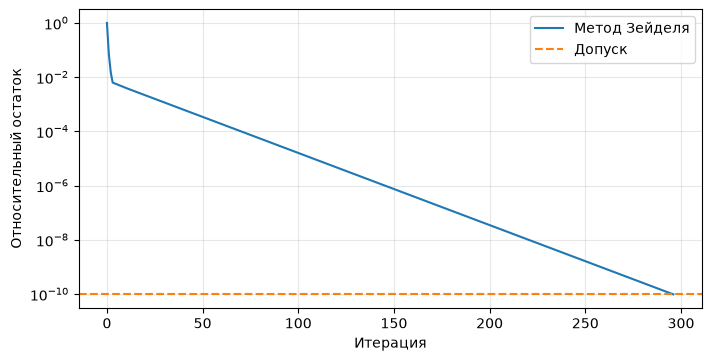

После 296 итераций относительный остаток изменился с 1 до 9.72e-11. Метод завершился со статусом «достигнут заданный допуск».

In [5]:
TOL = 1e-10
MAX_ITER = 20_000
def prepare_seidel(matrix):
    lower = np.tril(matrix)
    iteration_matrix = solve_triangular(lower, -np.triu(matrix, k=1), lower=True)
    radius = np.max(np.abs(np.linalg.eigvals(iteration_matrix)))
    return lower, radius


def solve_seidel(matrix, rhs, lower, tolerance, max_iterations):
    beta = np.zeros_like(rhs)
    residual = rhs.copy()
    rhs_norm = np.linalg.norm(rhs)
    history = [np.linalg.norm(residual) / rhs_norm]
    status = "Достигнут лимит итераций"

    for _ in range(max_iterations):
        beta += solve_triangular(lower, residual, lower=True)
        residual = rhs - matrix @ beta
        current_residual = np.linalg.norm(residual) / rhs_norm
        history.append(current_residual)
        if not np.isfinite(current_residual):
            status = "Остаток перестал быть конечным"
            break
        if current_residual <= tolerance:
            status = "Достигнут заданный допуск"
            break

    return beta, history, status


lower, rho = prepare_seidel(A)
forecast = (
    "ожидается сходимость из нулевого приближения" if rho < 1
    else "спектральное условие сходимости для произвольного начального приближения не выполнено"
)
display(Markdown(f"Спектральный радиус ρ(T) = {rho:.8f}, поэтому {forecast}."))

beta_gs, residual_history, gs_status = solve_seidel(A, b, lower, TOL, MAX_ITER)
iteration = len(residual_history) - 1

display(pd.Series({
    "Статус": gs_status,
    "Итераций": iteration,
    "Относительный остаток": f"{residual_history[-1]:.2e}",
}).to_frame("Результат"))
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.semilogy(residual_history, label="Метод Зейделя")
ax.axhline(TOL, color="tab:orange", linestyle="--", label="Допуск")
ax.set(xlabel="Итерация", ylabel="Относительный остаток")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

display(Markdown(
    f"После {iteration} итераций относительный остаток изменился "
    f"с {residual_history[0]:.2g} до {residual_history[-1]:.2e}. "
    f"Метод завершился со статусом «{gs_status.lower()}»."
))

Итоговый относительный остаток немного ниже порога остановки. Критерий отслеживает точность решения нормальных уравнений. Качество прогноза оценивается отдельно по тестовому RMSE в разделе 6.

### 5.1. Влияние масштаба на прямой и итерационный методы

Центрирование и изменение масштаба признаков при наличии свободного члена сохраняют пространство линейных прогнозов. При этом меняются численные свойства задачи. В частности, центрирование делает столбцы признаков ортогональными столбцу единиц, а деление на стандартное отклонение выравнивает масштабы признаков. Эти изменения влияют на обусловленность и на скорость итераций Зейделя.

Дополнительную проверку выполняем на обучающей матрице до стандартизации со столбцом единиц. Для метода Зейделя сохраняем нулевое начальное приближение, допуск и лимит итераций. Сходимость оцениваем по спектральному радиусу. При сравнении LU и SVD используем относительное расхождение их обучающих прогнозов в исходной шкале целевой переменной.

In [6]:
A_raw = X_train_raw.T @ X_train_raw
b_raw = X_train_raw.T @ y_train
lower_raw, rho_raw = prepare_seidel(A_raw)
_, raw_history, raw_status = solve_seidel(A_raw, b_raw, lower_raw, TOL, MAX_ITER)

display(pd.DataFrame({
    "ρ(T)": [rho_raw, rho],
    "Число итераций": [len(raw_history) - 1, iteration],
    "Итоговый относительный остаток": [raw_history[-1], residual_history[-1]],
    "Статус": [raw_status, gs_status],
}, index=["До стандартизации", "После стандартизации"]).style.format({
    "ρ(T)": "{:.8f}", "Итоговый относительный остаток": "{:.2e}",
}))

,ρ(T),Число итераций,Итоговый относительный остаток,Статус
До стандартизации,0.99976506,20000,1.07e-06,Достигнут лимит итераций
После стандартизации,0.94056686,296,9.72e-11,Достигнут заданный допуск


До стандартизации метод Зейделя приблизился к решению, но по достижении лимита его остаток был ещё примерно в 10 700 раз выше заданного допуска. Прогнозы прямого метода и SVD при этом практически совпали в обеих шкалах. В этом опыте влияние масштаба сильнее всего проявилось в скорости итераций.

## 6. Решение через SVD (§ 1.4.4)

Сингулярное разложение (SVD) представляет матрицу $X$ произведением $U\Sigma V^\top$. Столбцы $V$ задают ортонормированные направления в пространстве коэффициентов, столбцы $U$ задают соответствующие направления в пространстве наблюдений, а диагональ $\Sigma$ содержит сингулярные значения. Чтобы решить задачу МНК, вектор $y$ проектируют на направления $U$, делят координаты на соответствующие ненулевые сингулярные значения и переводят результат в исходные координаты через $V$. При потере ранга псевдообратная матрица даёт решение минимальной евклидовой нормы среди решений МНК.

Для $X=U\Sigma V^\top$ вычисляем псевдообратное решение
$$
\hat\beta_{\mathrm{SVD}}=
V_r\Sigma_r^{-1}U_r^\top y.
$$
В сумму входят направления с $\sigma_i>\tau$, где допуск определён в разделе 3. Сравниваем коэффициенты, оба относительных остатка и RMSE. Дополнительная библиотечная проверка использует `numpy.linalg.lstsq` с тем же относительным порогом.

In [7]:
def solve_svd(matrix, rhs):
    left, singular_values, right_t = np.linalg.svd(matrix, full_matrices=False)
    keep = singular_values > rank_threshold(matrix, singular_values)
    return right_t[keep].T @ ((left[:, keep].T @ rhs) / singular_values[keep])


beta_svd = solve_svd(X_train, y_train)
beta_lu_raw = solve_lu(A_raw, b_raw)
beta_svd_raw = solve_svd(X_train_raw, y_train)
prediction_gap_raw = np.linalg.norm(X_train_raw @ (beta_lu_raw - beta_svd_raw)) / np.linalg.norm(y_train)
prediction_gap_scaled = np.linalg.norm(X_train @ (beta_lu - beta_svd)) / np.linalg.norm(y_train)
display(pd.DataFrame({
    "Масштаб признаков": ["Исходный", "Стандартизованный"],
    "‖X(β_LU − β_SVD)‖₂ / ‖y‖₂": [prediction_gap_raw, prediction_gap_scaled],
}).set_index("Масштаб признаков").style.format("{:.2e}"))
relative_cutoff = max(X_train.shape) * np.finfo(X_train.dtype).eps
beta_lstsq = np.linalg.lstsq(X_train, y_train, rcond=relative_cutoff)[0]
np.testing.assert_allclose(beta_svd, beta_lstsq, rtol=1e-10, atol=1e-10)

baseline_solutions = {"LU": beta_lu}
if "Холецкий" in direct_solutions:
    baseline_solutions["Холецкий"] = direct_solutions["Холецкий"]
baseline_solutions.update({"Зейдель": beta_gs, "SVD": beta_svd})
baseline = pd.DataFrame({
    name: {
        **baseline_metrics(beta),
        "‖β − β_SVD‖₂": np.linalg.norm(beta - beta_svd),
    }
    for name, beta in baseline_solutions.items()
}).T

display(pd.DataFrame(baseline_solutions, index=coefficient_names).style.format("{:.6f}"))
display(baseline.style.format("{:.5g}"))
display(Markdown(
    f"На исходной стандартизованной задаче расхождение коэффициентов LU и SVD "
    f"составило {baseline.loc['LU', '‖β − β_SVD‖₂']:.2e}, а метода Зейделя и SVD — "
    f"{baseline.loc['Зейдель', '‖β − β_SVD‖₂']:.2e}. "
    f"Тестовый RMSE для SVD равен {baseline.loc['SVD', 'RMSE тест, МПа']:.3f} МПа. "
    "SVD решает задачу через исходную матрицу X, сохраняя её сингулярные направления."
))

,‖X(β_LU − β_SVD)‖₂ / ‖y‖₂
Масштаб признаков,
Исходный,5.69e-14
Стандартизованный,5.67e-15


,LU,Холецкий,Зейдель,SVD
Свободный член,36.023049,36.023049,36.023049,36.023049
cement,12.621078,12.621078,12.621078,12.621078
slag,8.473261,8.473261,8.473261,8.473261
fly_ash,5.131771,5.131771,5.131771,5.131771
water,-3.423330,-3.423330,-3.423330,-3.423330
superplasticizer,2.109488,2.109488,2.109488,2.109488
coarse_aggregate,1.387876,1.387876,1.387876,1.387876
fine_aggregate,1.658256,1.658256,1.658256,1.658256
age,6.908694,6.908694,6.908694,6.908694


,‖β‖₂,Отн. остаток норм. ур.,Отн. остаток МНК,"RMSE обучение, МПа","RMSE тест, МПа",‖β − β_SVD‖₂
LU,40.295,7.267e-17,0.25883,10.314,10.646,1.1553e-12
Холецкий,40.295,2.366e-16,0.25883,10.314,10.646,1.1733e-12
Зейдель,40.295,9.7202e-11,0.25883,10.314,10.646,9.9511e-08
SVD,40.295,2.268e-15,0.25883,10.314,10.646,0


На исходной стандартизованной задаче расхождение коэффициентов LU и SVD составило 1.16e-12, а метода Зейделя и SVD — 9.95e-08. Тестовый RMSE для SVD равен 10.646 МПа. SVD решает задачу через исходную матрицу X, сохраняя её сингулярные направления.

Все четыре метода дали одинаковый тестовый RMSE с точностью до 0,001 МПа. На этой матрице полного ранга различия в способе вычисления коэффициентов оказались малы по сравнению с ошибкой линейной аппроксимации.

## 7. Искусственное ухудшение обусловленности (§ 1.4.5)

Если один столбец почти выражается через другие, возникает направление изменения коэффициентов, вдоль которого прогноз меняется слабо. Этому направлению соответствует малое сингулярное значение. Множитель $1/\sigma_i$ в решении через SVD показывает, почему даже небольшая проекция отклика на соответствующий левый сингулярный вектор может дать большую компоненту коэффициентов.

К стандартизованным признакам добавляем столбец
$$x_{\mathrm{new}}=x_{\mathrm{cement}}+0.5\,x_{\mathrm{slag}}+\varepsilon z.$$
Значения $\varepsilon$ равны $10^{-2}$, $10^{-6}$ и $0$. Шум $z$ генерируется один раз для всех строк с фиксированным seed 43. На обучении его среднее приводят к нулю, а дисперсию - к единице. К тестовому шуму применяют то же преобразование. Во всех опытах используют одни и те же шум и разбиение.

В численно вырожденном случае останавливаем LU после проверки ранга $X$. Это исключает решение сингулярной системы, которая при округлении в $X^\top X$ может дать формально ненулевой ведущий элемент. SVD использует только направления выше порога. При $\varepsilon=0$ дополнительный столбец выражается через исходные, поэтому в точной арифметике пространство прогнозов сохраняется.

In [8]:
noise = np.random.default_rng(SEED + 1).standard_normal(len(data))
noise_mean = noise[train_idx].mean()
noise_std = noise[train_idx].std()
z_train = (noise[train_idx] - noise_mean) / noise_std
z_test = (noise[test_idx] - noise_mean) / noise_std
assert np.isclose(z_train.var(), 1.0)

j, k = (coefficient_names.index(feature) for feature in ("cement", "slag"))
c = 0.5
dependence_results = []
dependence_diagnostics = []
dependence_coefficients = {}

for epsilon in (1e-2, 1e-6, 0.0):
    train_new = X_train[:, j] + c * X_train[:, k] + epsilon * z_train
    test_new = X_test[:, j] + c * X_test[:, k] + epsilon * z_test
    X_train_aug = np.column_stack((X_train, train_new))
    X_test_aug = np.column_stack((X_test, test_new))
    A_aug = X_train_aug.T @ X_train_aug
    b_aug = X_train_aug.T @ y_train
    diagnostics, singular_values = matrix_diagnostics(X_train_aug)
    label = f"{epsilon:g}"
    dependence_diagnostics.append({
        "ε": label, **diagnostics, "σ_min": singular_values[-1],
    })

    for name in ("LU", "SVD"):
        result = {"ε": label, "Метод": name}
        try:
            if name == "LU":
                if diagnostics["Ранг"] < X_train_aug.shape[1]:
                    raise np.linalg.LinAlgError("X не имеет полного столбцового ранга")
                beta = solve_lu(A_aug, b_aug)
            else:
                beta = solve_svd(X_train_aug, y_train)
            if not np.isfinite(beta).all():
                raise FloatingPointError("Получены нечисловые или бесконечные коэффициенты")
            dependence_coefficients[label, name] = beta
            result.update(evaluate(beta, X_train_aug, X_test_aug, A_aug, b_aug))
            result["Статус"] = "Решение получено"
        except (np.linalg.LinAlgError, LinAlgWarning, FloatingPointError) as error:
            result["Статус"] = str(error)
        dependence_results.append(result)

dependence_matrix = pd.DataFrame(dependence_diagnostics).set_index("ε")
dependence = pd.DataFrame(dependence_results).set_index(["ε", "Метод"])
dependence["‖β_LU − β_SVD‖₂"] = np.nan
for label in dependence_matrix.index:
    if (label, "LU") in dependence_coefficients and (label, "SVD") in dependence_coefficients:
        dependence.loc[(label, "LU"), "‖β_LU − β_SVD‖₂"] = np.linalg.norm(
            dependence_coefficients[label, "LU"] - dependence_coefficients[label, "SVD"]
        )

display(dependence_matrix.style.format({"Ранг": "{:.0f}", **{
    column: "{:.4g}" for column in dependence_matrix.columns if column != "Ранг"
}}))
display(dependence.style.format({
    column: "{:.5g}" for column in dependence.columns if column != "Статус"
}, na_rep="—"))

display(Markdown(
    f"При уменьшении ε с 0.01 до 1e-6 обусловленность X выросла "
    f"с {dependence_matrix.loc['0.01', 'κ₂(X)']:.3g} "
    f"до {dependence_matrix.loc['1e-06', 'κ₂(X)']:.3g}. Норма коэффициентов SVD "
    f"выросла с {dependence.loc[('0.01', 'SVD'), '‖β‖₂']:.3g} "
    f"до {dependence.loc[('1e-06', 'SVD'), '‖β‖₂']:.3g}. "
    f"При ε = 0 ранг уменьшился до {dependence_matrix.loc['0', 'Ранг']}, "
    "а SVD вернул решение минимальной нормы в прежнем пространстве прогнозов."
))

,Ранг,Допуск,κ₂(X),κ₂(XᵀX),σ_min
ε,,,,,
0.01,10,8.422e-12,241,5.81e+04,0.1905
1e-06,10,8.423e-12,2.411e+06,5.825e+12,1.905e-05
0,9,8.423e-12,inf,inf,6.952e-15


При уменьшении ε с 0.01 до 1e-6 обусловленность X выросла с 241 до 2.41e+06. Норма коэффициентов SVD выросла с 117 до 1.21e+06. При ε = 0 ранг уменьшился до 9, а SVD вернул решение минимальной нормы в прежнем пространстве прогнозов.

При $\varepsilon=10^{-6}$ относительный остаток МНК и тестовая ошибка почти совпали у LU и SVD, хотя расстояние между их векторами коэффициентов составило около $3.05\cdot10^3$. Большая разница сосредоточена преимущественно в направлении, слабо влияющем на произведение $X\beta$.

## 8. Сокращение размерности (§ 1.4.6)

Усечённое SVD оставляет направления с наибольшими сингулярными значениями. Для центрированных признаков эти направления совпадают с главными компонентами и описывают наибольшую долю дисперсии признаков. Отбор основан на матрице признаков, поэтому качество сохранённых компонент для прогноза прочности оценивается отдельно по RMSE.

Выполняем усечённое SVD стандартизованной обучающей матрицы признаков. Столбец единиц обрабатываем отдельно и сохраняем при всех $k$. Для $k=1,2,3$ и полного доступного ранга используем первые $k$ правых сингулярных векторов $V_k$. Обе части проектируем одним преобразованием $Z=XV_k$ по признакам без столбца единиц. В редуцированной задаче добавляем к $Z$ столбец единиц.

Доля объяснённой дисперсии равна $\sum_{i=1}^k\sigma_i^2 / \sum_i\sigma_i^2$. Число обусловленности рассчитываем для фактической редуцированной матрицы со свободным членом.

,Доля дисперсии,κ₂(X),"RMSE обучение, МПа","RMSE тест, МПа"
k,,,,
1,28.04%,1.498,17.0053,15.3419
2,45.98%,1.498,16.8388,14.9605
3,62.71%,1.498,13.1798,14.2547
8,100.00%,8.608,10.3142,10.6456


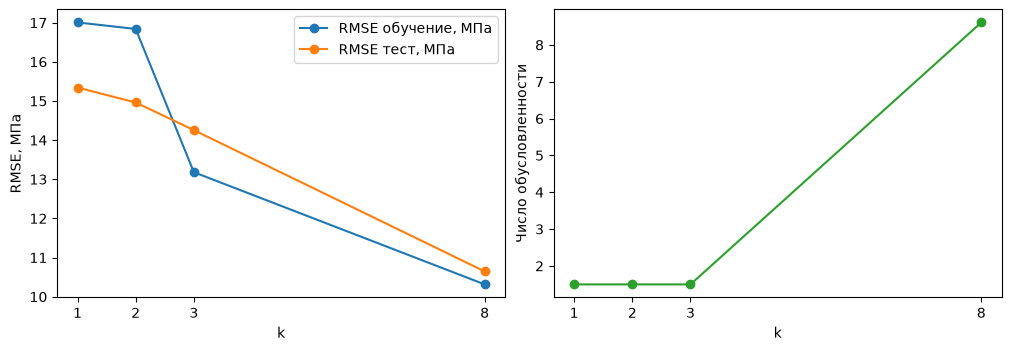

Первые три направления объясняют 62.7% дисперсии. При k = 3 число обусловленности равно 1.50, тестовый RMSE — 14.255 МПа. При полном ранге эти значения составляют соответственно 8.61 и 10.646 МПа.

In [9]:
_, feature_sigma, feature_right_t = np.linalg.svd(train_scaled, full_matrices=False)
feature_rank = int(np.count_nonzero(feature_sigma > rank_threshold(train_scaled, feature_sigma)))
kept_dimensions = [1, 2, 3, feature_rank]
reduction_rows = []

for dimension in kept_dimensions:
    directions = feature_right_t[:dimension].T
    reduced_train = add_intercept(train_scaled @ directions)
    reduced_test = add_intercept(test_scaled @ directions)
    beta_reduced = solve_svd(reduced_train, y_train)
    reduction_rows.append({
        "k": dimension,
        "Доля дисперсии": np.sum(feature_sigma[:dimension] ** 2) / np.sum(feature_sigma ** 2),
        "κ₂(X)": np.linalg.cond(reduced_train),
        "RMSE обучение, МПа": rmse(y_train, reduced_train @ beta_reduced),
        "RMSE тест, МПа": rmse(y_test, reduced_test @ beta_reduced),
    })

reduction = pd.DataFrame(reduction_rows).set_index("k")
np.testing.assert_allclose(reduced_test @ beta_reduced, X_test @ beta_svd, atol=1e-10)
display(reduction.style.format({
    "Доля дисперсии": "{:.2%}", "κ₂(X)": "{:.3f}",
    "RMSE обучение, МПа": "{:.4f}", "RMSE тест, МПа": "{:.4f}",
}))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
reduction[["RMSE обучение, МПа", "RMSE тест, МПа"]].plot(ax=axes[0], marker="o")
reduction["κ₂(X)"].plot(ax=axes[1], marker="o", color="tab:green")
axes[0].set(ylabel="RMSE, МПа", xticks=kept_dimensions)
axes[1].set(ylabel="Число обусловленности", xticks=kept_dimensions)
plt.show()

display(Markdown(
    f"Первые три направления объясняют {reduction.loc[3, 'Доля дисперсии']:.1%} "
    f"дисперсии. При k = 3 число обусловленности равно {reduction.loc[3, 'κ₂(X)']:.2f}, "
    f"тестовый RMSE — {reduction.loc[3, 'RMSE тест, МПа']:.3f} МПа. "
    f"При полном ранге эти значения составляют соответственно "
    f"{reduction.loc[feature_rank, 'κ₂(X)']:.2f} и "
    f"{reduction.loc[feature_rank, 'RMSE тест, МПа']:.3f} МПа."
))

Переход от одной компоненты к трём снизил тестовый RMSE с 15,342 до 14,255 МПа при практически одинаковом числе обусловленности. Полный набор компонент дал наименьшую тестовую ошибку среди проверенных вариантов.

## 9. Ridge-регуляризация (§ 1.4.7)

Ridge-регрессия добавляет к сумме квадратов ошибок штраф $\lambda\|D\beta\|_2^2$. Чем больше $\lambda$, тем сильнее штраф за большие коэффициенты признаков. Для центрированных признаков действие штрафа можно описать в сингулярных направлениях. В каждом из них обратный множитель $1/\sigma_i$ заменяется на $\sigma_i/(\sigma_i^2+\lambda)$, что особенно сильно подавляет вклад направлений с малыми сингулярными значениями.

Решаем систему $(X^\top X+\lambda D^\top D)\beta_\lambda=X^\top y$, где $D=\operatorname{diag}(0,1,\ldots,1)$. Используем семь значений $\lambda$ от $10^{-4}$ до $10^5$ с одинаковым шагом по логарифму. Малое значение даёт почти нерегуляризованное решение. Верхняя граница позволяет проверить режим сильного сжатия коэффициентов.

**Правило выбора $\lambda$.** Минимизируем средний RMSE по пяти групповым фолдам обучающей части. При равном среднем выбираем меньшее $\lambda$. Стандартизатор заново обучаем внутри каждого фолда. В системе используем сумму квадратов остатков без деления на размер обучающей выборки. Для сопоставимой силы штрафа внутри фолда умножаем $\lambda$ на отношение размера его обучающей части к размеру полной обучающей части. Тестовый RMSE используем для итогового сравнения.

,κ₂ регуляризованной системы,‖β‖₂,‖Dβ‖₂,"RMSE обучение, МПа","RMSE тест, МПа","Средний RMSE по CV, МПа"
λ,,,,,,
0.0001,74.095,40.295,18.055,10.314,10.646,10.498
0.003162,74.086,40.294,18.054,10.314,10.646,10.498
0.1,73.804,40.281,18.024,10.314,10.646,10.498
3.162,65.888,39.916,17.194,10.317,10.662,10.5
100,15.62,37.952,11.946,10.579,10.993,10.741
3162,6.0713,36.136,2.8596,14.757,13.64,14.765
1e+05,123.31,36.023,0.11818,16.94,15.168,16.925


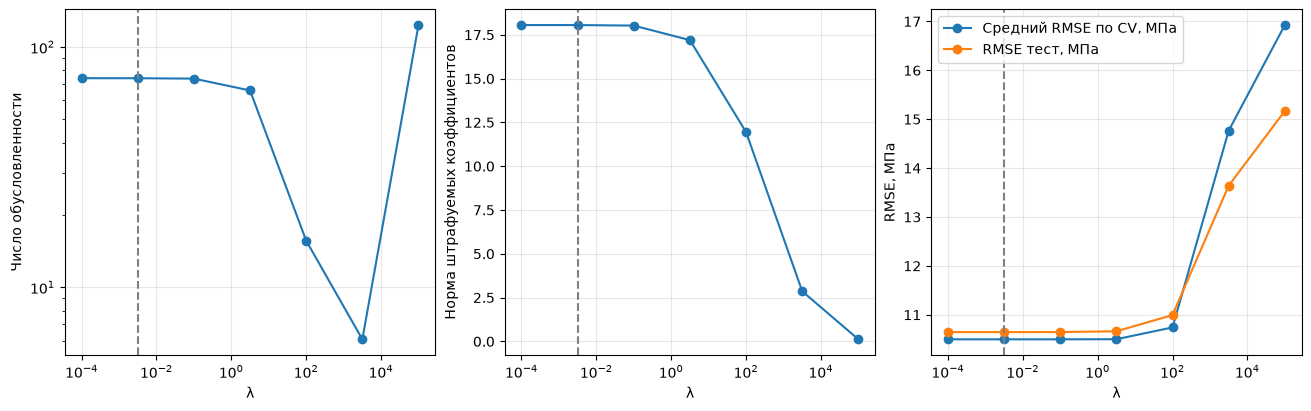

По кросс-валидации выбрано λ = 0.003162. Средний RMSE по фолдам равен 10.498 МПа, тестовый RMSE — 10.646 МПа. При λ = 100000 норма штрафуемых коэффициентов составляет 0.118 против 18.055 при наименьшем λ.

In [10]:
def ridge_system(normal_matrix, penalty, regularization):
    return normal_matrix + regularization * penalty


penalty = np.diag([0.0, *np.ones(len(FEATURES))])
lambdas = np.logspace(-4, 5, num=7)
group_cv = GroupKFold(n_splits=5)
cv_errors = np.empty((len(lambdas), group_cv.n_splits))

for fold, (fit_idx, val_idx) in enumerate(
    group_cv.split(train_raw, y_train, groups=groups[train_idx])
):
    fold_scaler = StandardScaler()
    X_fit = add_intercept(fold_scaler.fit_transform(train_raw[fit_idx]))
    X_val = add_intercept(fold_scaler.transform(train_raw[val_idx]))
    A_fold = X_fit.T @ X_fit
    b_fold = X_fit.T @ y_train[fit_idx]
    fold_scale = len(fit_idx) / len(train_idx)
    for row, regularization in enumerate(lambdas):
        A_reg = ridge_system(A_fold, penalty, regularization * fold_scale)
        beta_fold = solve_lu(A_reg, b_fold)
        cv_errors[row, fold] = rmse(y_train[val_idx], X_val @ beta_fold)

mean_cv_rmse = cv_errors.mean(axis=1)
selected_lambda = lambdas[np.argmin(mean_cv_rmse)]
ridge_rows = []

for regularization, cv_rmse in zip(lambdas, mean_cv_rmse):
    A_reg = ridge_system(A, penalty, regularization)
    beta_ridge = solve_lu(A_reg, b)
    ridge_rows.append({
        "λ": regularization,
        "κ₂ регуляризованной системы": np.linalg.cond(A_reg),
        "‖β‖₂": np.linalg.norm(beta_ridge),
        "‖Dβ‖₂": np.linalg.norm(penalty @ beta_ridge),
        "RMSE обучение, МПа": rmse(y_train, X_train @ beta_ridge),
        "RMSE тест, МПа": rmse(y_test, X_test @ beta_ridge),
        "Средний RMSE по CV, МПа": cv_rmse,
    })

ridge = pd.DataFrame(ridge_rows).set_index("λ")
display(ridge.style.format("{:.5g}").format_index("{:.4g}", axis=0))

fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
ridge["κ₂ регуляризованной системы"].plot(ax=axes[0], loglog=True, marker="o")
ridge["‖Dβ‖₂"].plot(ax=axes[1], logx=True, marker="o")
ridge[["Средний RMSE по CV, МПа", "RMSE тест, МПа"]].plot(ax=axes[2], logx=True, marker="o")
axes[0].set(ylabel="Число обусловленности")
axes[1].set(ylabel="Норма штрафуемых коэффициентов")
axes[2].set(ylabel="RMSE, МПа")
for ax in axes:
    ax.axvline(selected_lambda, color="0.5", linestyle="--")
    ax.grid(alpha=0.3)
plt.show()

selected_ridge = ridge.loc[selected_lambda]
display(Markdown(
    f"По кросс-валидации выбрано λ = {selected_lambda:.4g}. "
    f"Средний RMSE по фолдам равен {selected_ridge['Средний RMSE по CV, МПа']:.3f} МПа, "
    f"тестовый RMSE — {selected_ridge['RMSE тест, МПа']:.3f} МПа. "
    f"При λ = {lambdas[-1]:.0f} норма штрафуемых коэффициентов составляет "
    f"{ridge.iloc[-1]['‖Dβ‖₂']:.3f} против {ridge.iloc[0]['‖Dβ‖₂']:.3f} "
    "при наименьшем λ."
))

При $\lambda\approx3162$ регуляризованная система лучше всего обусловлена среди рассмотренных вариантов, однако её тестовый RMSE равен 13,640 МПа. Выбор по кросс-валидации дал меньший штраф и почти сохранил прогноз обычного МНК.

## 10. Итоговое сравнение

RMSE рассчитываем на одних и тех же обучающих и тестовых наблюдениях, поэтому можем напрямую сравнивать его между методами. Остаток нормальных уравнений характеризует точность решения системы, а тестовый RMSE характеризует качество прогноза на отложенных наблюдениях.

Для исходной задачи сопоставляем решения МНК, усечённое SVD и ridge с выбранным по кросс-валидации параметром. Для усечённого SVD приводим заранее заданный вариант с тремя направлениями. Результаты искусственного ухудшения обусловленности приводим в отдельной таблице раздела 7.

In [11]:
rmse_columns = ["RMSE обучение, МПа", "RMSE тест, МПа"]
comparison = pd.concat([
    baseline[rmse_columns],
    reduction.loc[[3], rmse_columns].rename(index={3: "Усечённое SVD, k = 3"}),
    ridge.loc[[selected_lambda], rmse_columns].rename(index={selected_lambda: "Ridge по CV"}),
])
display(comparison.style.format("{:.4f}"))

,"RMSE обучение, МПа","RMSE тест, МПа"
LU,10.3142,10.6456
Холецкий,10.3142,10.6456
Зейдель,10.3142,10.6456
SVD,10.3142,10.6456
"Усечённое SVD, k = 3",13.1798,14.2547
Ridge по CV,10.3142,10.6456


У всех четырёх решений МНК и ridge с выбранным штрафом тестовый RMSE совпал до четвёртого знака после запятой и составил 10,6456 МПа. Усечение до трёх компонент увеличило ошибку и на обучении, и на тесте. На этой выборке выигрыш в обусловленности при таком усечении сопровождался потерей качества прогноза.

## 11. Вопросы для итогового вывода (§ 1.8)

### 1. Как стандартизация повлияла на обусловленность матрицы и поведение методов?

Число обусловленности $X$ уменьшилось с 1.06e+05 до 8.61, а число обусловленности нормальных уравнений снизилось с 1.13e+10 до 74.1. Ранг сохранился. Спектральный радиус итерации снизился с 0.999765 до 0.940567. До стандартизации за 20000 итераций остаток составил 1.07e-06. После стандартизации допуск достигнут за 296 итераций. Относительное расхождение прогнозов LU и SVD изменилось с 5.69e-14 до 5.67e-15.

Полный ранг $9$ сохранился, поскольку стандартизация при наличии свободного члена соответствует обратимой замене столбцов. При этом выравнивание их масштабов уменьшило разброс сингулярных значений. Равенство $\kappa_2(X^\top X)=\kappa_2(X)^2$ объясняет, почему выигрыш в обусловленности нормальных уравнений выражен сильнее. Относительное различие прогнозов LU и SVD было очень малым в обеих шкалах.

### 2. Совпали ли решения прямого метода, итерационного метода и SVD? Чем объясняются различия?

На стандартизованной задаче решения совпали с численной точностью. Расстояния между коэффициентами LU и SVD, а также Зейделя и SVD равны 1.16e-12 и 9.95e-08. Расхождение LU и SVD связано с округлением при формировании и решении нормальных уравнений. Для Зейделя также влияет остановка по конечному допуску.

Разложение Холецкого дало коэффициенты, отличающиеся от SVD по евклидовой норме на $1.17\cdot10^{-12}$. У всех четырёх методов совпали обучающий и тестовый RMSE с точностью до трёх знаков после запятой (10,314 и 10,646 МПа соответственно). Разница в точности решения системы в этом опыте практически не отразилась на прогнозе.

### 3. Соответствовала ли фактическая сходимость итерационного метода спектральному прогнозу?

Да. Спектральный радиус равен 0.940567, поэтому ожидалась сходимость. Допуск достигнут за 296 итераций, итоговый относительный остаток равен 9.72e-11. Близость спектрального радиуса к единице объясняет медленное уменьшение остатка на поздних итерациях.

Механизм сходимости задаёт формула $e^{(k+1)}=Te^{(k)}$, где $e^{(k)}$ - ошибка коэффициентов на шаге $k$. Спектральный радиус задаёт асимптотический темп, а фактическое число шагов зависит также от начальной ошибки и условия остановки. До стандартизации $\rho(T)=0.999765<1$, поэтому сходимость также ожидается, хотя за отведённые 20 000 итераций допуск достигнут не был.

### 4. Как приближение к потере ранга повлияло на коэффициенты, остаток и качество прогноза?

При ε = 1e-6 норма коэффициентов SVD достигла 1.21e+06, тогда как при ε = 0.01 она равна 117. Относительный остаток МНК SVD для этих двух вариантов составил соответственно 0.25804 и 0.25804. Тестовый RMSE в обоих случаях равен 10.767 МПа с указанным округлением. При ε = 1e-6 расстояние между коэффициентами LU и SVD составило 3.05e+03, при тестовом RMSE LU 10.768 МПа. Большие коэффициенты компенсируют друг друга вдоль почти зависимого направления. При ε = 0 LU остановился по проверке ранга, а SVD отбросил нулевое направление.

В обоих опытах с $\varepsilon>0$ ранг равен 10. При уменьшении $\varepsilon$ минимальное сингулярное значение падает с $0.1905$ до $1.905\cdot10^{-5}$, что усиливает чувствительность коэффициентов. При $\varepsilon=0$ ранг падает до 9, а тестовый RMSE SVD возвращается к 10,646 МПа, как у модели с исходными признаками. Точно зависимый столбец сохраняет прежнее пространство линейных прогнозов.

### 5. Как выбранное сокращение размерности повлияло на устойчивость и ошибку прогноза?

При k = 3 число обусловленности снизилось с 8.61 до 1.5. Тестовый RMSE изменился с 10.646 до 14.255 МПа. Усечение удаляет плохо обусловленные направления, которые могут содержать информацию о прочности даже при малой объяснённой дисперсии признаков.

Три компоненты сохранили 62,7% дисперсии признаков, а тестовый RMSE вырос на 3,609 МПа. Среди проверенных $k=1,2,3$ наименьшую тестовую ошибку дали три компоненты. Во всех этих вариантах число обусловленности было около 1,50, поэтому различие в ошибках связано с тем, какие направления доступны модели.

### 6. Как изменение λ повлияло на обусловленность, коэффициенты и качество ridge-регрессии?

Число обусловленности регуляризованной системы сначала снизилось с 74.1 до 6.07, а при наибольшем λ выросло до 123. При большом λ растут собственные числа в штрафуемых направлениях, а собственное число, связанное со свободным членом, остаётся прежним. Норма штрафуемых коэффициентов уменьшилась с 18.1 до 0.118. При наибольшем λ тестовый RMSE равен 15.168 МПа против 10.646 МПа у варианта, выбранного по CV (λ = 0.003162).

Минимум числа обусловленности среди проверенных значений достигнут при $\lambda\approx3162$. При этом тестовый RMSE составил 13,640 МПа. Значение $\lambda$, выбранное по кросс-валидации, дало более точный прогноз при более высоком числе обусловленности. При сильном штрафе коэффициенты признаков близки к нулю, и прогноз приближается к средней прочности на обучении.

### 7. Какой способ решения оказался наиболее подходящим для исследованной задачи и почему?

Для численного решения МНК наиболее подходящим оказался SVD. На исходной стандартизованной матрице он дал ту же точность прогноза, что LU, и сохранил возможность получить решение минимальной нормы при потере ранга. Тестовые RMSE полного SVD и ridge, выбранного по CV, составили 10.646 и 10.646 МПа соответственно.

Практическое преимущество полного SVD в этом исследовании состоит в решении МНК по исходной матрице $X$ без формирования $X^\top X$. На хорошо обусловленной стандартизованной задаче LU и Холецкий дали ту же тестовую ошибку. Ridge с выбранным штрафом тоже показал сопоставимый результат, а усечённое SVD при $k=3$ ухудшило прогноз. По этим опытам преимущество полного SVD проявилось прежде всего в работе с плохо обусловленной матрицей и потерей ранга.

## 12. Вклад участников команды

Лабораторную работу выполнили совместно Самойленко Артём и Архипов Прохор. Отдельные задания между участниками не распределялись. Оба готовили данные, реализовывали методы, проверяли результаты и оформляли выводы. Вклад в каждый пункт работы был примерно равным.